### Installing required libraries

In [275]:
!pip install seaborn
!pip install missingno
!pip install xgboost
!pip install catboost
!pip install regex
!pip install scikit-learn
!pip install pandas
!pip install numpy
!pip install imblearn
!pip install lightgbm
!pip install polar



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Importing all libraries 

In [276]:
import pandas as pd   # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np   # linear algebra
import matplotlib.pyplot as plt  #graphs and plots
import seaborn as sns   #data visualizations 
import csv # Some extra functionalities for csv  files - reading it as a dictionary
from lightgbm import LGBMClassifier #sklearn is for machine learning and statistical modeling including classification, regression, clustering and dimensionality reduction 

from sklearn.model_selection import train_test_split, cross_validate   #break up dataset into train and test sets

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler


# importing python library for working with missing data
import missingno as msno
# To install missingno use: !pip install missingno
import re    # This library is used to perform regex pattern matching

# import various functions from sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, classification_report, make_scorer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

### Import additional items as needed...

In [277]:
from sklearn.model_selection import KFold,cross_val_score, RepeatedStratifiedKFold,StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.compose import make_column_transformer
from imblearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score,\
                            precision_score, recall_score, roc_auc_score,\
                            classification_report, f1_score # removed plot_roc_curve and plot_confusion_matrix as they are deprecated

import plotly 
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

import warnings
warnings.filterwarnings("ignore")

### Loading CSV data 

In [278]:
diabetes = pd.read_csv('C:/Users/paulq/Desktop/Applied Health Informatics/550 - Applied Healthcare Analytics/Python/DiabetesData/diabetic_data.csv')

### CLEANING AND TRANSFORMING THE DATASET

In [279]:
# discharge_disposition_id	description
# 1	Discharged to home
# 2	Discharged/transferred to another short term hospital
# 3	Discharged/transferred to SNF
# 4	Discharged/transferred to ICF
# 5	Discharged/transferred to another type of inpatient care institution
# 6	Discharged/transferred to home with home health service
# 7	Left AMA
# 8	Discharged/transferred to home under care of Home IV provider
# 9	Admitted as an inpatient to this hospital
# 10	Neonate discharged to another hospital for neonatal aftercare
# 11	Expired
# 12	Still patient or expected to return for outpatient services
# 13	Hospice / home
# 14	Hospice / medical facility
# 15	Discharged/transferred within this institution to Medicare approved swing bed
# 16	Discharged/transferred/referred another institution for outpatient services
# 17	Discharged/transferred/referred to this institution for outpatient services
# 18	NULL
# 19	Expired at home. Medicaid only, hospice.
# 20	Expired in a medical facility. Medicaid only, hospice.
# 21	Expired, place unknown. Medicaid only, hospice.
# 22	Discharged/transferred to another rehab fac including rehab units of a hospital .
# 23	Discharged/transferred to a long term care hospital.
# 24	Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.
# 25	Not Mapped
# 26	Unknown/Invalid
# 30	Discharged/transferred to another Type of Health Care Institution not Defined Elsewhere
# 27	Discharged/transferred to a federal health care facility.
# 28	Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital
# 29	Discharged/transferred to a Critical Access Hospital (CAH).


In [280]:
# Removal of records from discharge disposition 11, 13, 14, 19, 20, 21 as these patients were either discharged to hospice care or died during their hospital stay.
diabetes = diabetes[~diabetes['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]

# Removal of NULL, Not Mapped, Unknown/Invalid values from discharge_disposition_id column. 
diabetes = diabetes[~diabetes['discharge_disposition_id'].isin([18, 25, 26])]

In [281]:
# Keep only Male and Female rows
diabetes = diabetes[diabetes['gender'].isin(['Male', 'Female'])].copy()

# Create indicator: 1 = Male, 0 = Female
diabetes['GenderMale'] = (diabetes['gender'] == 'Male').astype(int)

In [282]:
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [283]:
# Created a new column ERAdmission.
# ERAdmission = 1 if admission_type_id is 1 or 2 (Emergency/Urgent), otherwise 0.

diabetes['ERAdmission'] = diabetes['admission_type_id'].isin([1, 2]).astype(int)

In [284]:
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 0 if x == "No" else 1
)

In [285]:
# Created indicator column for readmission within 30 days
# readmit_less_30 = 1 if readmitted is "<30", else 0

diabetes['readmit_less_30'] = (diabetes['readmitted'] == '<30').astype(int)

In [286]:
diabetes['RaceCaucasian'] = (diabetes['race'] == 'Caucasian').astype(int)
diabetes['RaceAfricanAmerican'] = (diabetes['race'] == 'AfricanAmerican').astype(int)
diabetes['RaceOther'] = (~diabetes['race'].isin(['Caucasian', 'AfricanAmerican'])).astype(int)

In [287]:
# 1. Map ICD-9 codes
def categorize_icd9_chapter(code):
    """Maps ICD-9 codes to 17 main chapters + 2 supplemental categories"""
    if pd.isna(code):
        return "Missing"

    code_str = str(code).strip()

    # Supplemental codes
    if code_str.startswith('V'):
        return "V-codes: Factors Influencing Health Status"
    if code_str.startswith('E'):
        return "E-codes: External Causes of Injury"

    # Extract numeric part
    try:
        numeric_part = ''.join(filter(str.isdigit, code_str))
        if not numeric_part:
            return "Unmapped"
        code_num = int(numeric_part[:3])
    except:
        return "Unmapped"

    # ICD-9 chapter ranges
    chapter_map = {
        range(1, 140): "Infectious and Parasitic Diseases",
        range(140, 240): "Neoplasms (Cancers/Tumors)",
        range(240, 280): "Endocrine, Nutritional, Metabolic Diseases",
        range(280, 290): "Diseases of Blood and Blood-forming Organs",
        range(290, 320): "Mental Disorders",
        range(320, 390): "Diseases of Nervous System and Sense Organs",
        range(390, 460): "Diseases of Circulatory System",
        range(460, 520): "Diseases of Respiratory System",
        range(520, 580): "Diseases of Digestive System",
        range(580, 630): "Diseases of Genitourinary System",
        range(630, 680): "Complications of Pregnancy, Childbirth, Puerperium",
        range(680, 710): "Diseases of Skin and Subcutaneous Tissue",
        range(710, 740): "Diseases of Musculoskeletal System and Connective Tissue",
        range(740, 760): "Congenital Anomalies",
        range(760, 780): "Conditions Originating in Perinatal Period",
        range(780, 800): "Symptoms, Signs, Ill-defined Conditions",
        range(800, 1000): "Injury and Poisoning"
    }

    for code_range, chapter_name in chapter_map.items():
        if code_num in code_range:
            return chapter_name

    return "Unmapped"


In [288]:
# Applying categorization the priamry diagnosis column diag_1
diabetes['Primary_Diagnosis'] = diabetes['diag_1'].apply(categorize_icd9_chapter)
print("Created diag_1_chapter")

print("\nChapter Distribution for Primary Diagnosis (diag_1_chapter):")
print(diabetes['Primary_Diagnosis'].value_counts().head(20))


Created diag_1_chapter

Chapter Distribution for Primary Diagnosis (diag_1_chapter):
Primary_Diagnosis
Diseases of Circulatory System                              27836
Endocrine, Nutritional, Metabolic Diseases                  10802
Diseases of Respiratory System                               9576
Diseases of Digestive System                                 8715
Symptoms, Signs, Ill-defined Conditions                      7187
Injury and Poisoning                                         6558
Diseases of Genitourinary System                             4799
Diseases of Musculoskeletal System and Connective Tissue     4696
Neoplasms (Cancers/Tumors)                                   2984
Infectious and Parasitic Diseases                            2489
Diseases of Skin and Subcutaneous Tissue                     2402
Mental Disorders                                             2199
V-codes: Factors Influencing Health Status                   1492
Diseases of Nervous System and Sense Or

In [289]:
diabetes['diabetes_related'] = diabetes['Primary_Diagnosis'].str.contains(
    'Endocrine', case=False, na=False
).astype(int)


In [290]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'GenderMale', 'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanA

In [291]:
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'race', 'weight', 'gender',
    'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
    'payer_code', 'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum', 'A1Cresult',
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
    'change', 'readmitted'
], axis=1)

In [292]:
cleandiabetes.head()

,encounter_id,patient_nbr,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,ERAdmission,readmit_less_30,RaceCaucasian,RaceAfricanAmerican,RaceOther,Primary_Diagnosis,diabetes_related
1,149190,55629189,15,3,59,0,18,0,0,0,9,1,0,1,0,1,0,0,"Endocrine, Nutritional, Metabolic Diseases",1
2,64410,86047875,25,2,11,5,13,2,0,1,6,1,0,1,0,0,1,0,"Complications of Pregnancy, Childbirth, Puerpe...",0
3,500364,82442376,35,2,44,1,16,0,0,0,7,1,1,1,0,1,0,0,Infectious and Parasitic Diseases,0
4,16680,42519267,45,1,51,0,8,0,0,0,5,1,1,1,0,1,0,0,Neoplasms (Cancers/Tumors),0
5,35754,82637451,55,3,31,6,16,0,0,0,9,1,1,1,0,1,0,0,Diseases of Circulatory System,0


### Creating 3 Dataframes from cleandiabetes dataset

In [293]:
# Sub1: No changes (just a copy of cleandiabetes)
Sub1 = cleandiabetes.copy()

# Count how many times each patient appears
patient_counts = cleandiabetes['patient_nbr'].value_counts()

# Identify unique and duplicate patient IDs
unique_ids = patient_counts[patient_counts == 1].index
duplicate_ids = patient_counts[patient_counts > 1].index

# Sub2: Only unique patients (remove duplicates)
Sub2 = cleandiabetes[cleandiabetes['patient_nbr'].isin(unique_ids)].copy()

# Sub3: Only duplicate patients
Sub3 = cleandiabetes[cleandiabetes['patient_nbr'].isin(duplicate_ids)].copy()

In [294]:
print("Sub1 rows:", len(Sub1))
print("Sub2 rows:", len(Sub2))
print("Sub3 rows:", len(Sub3))

print("Unique patients:", len(unique_ids))
print("Duplicate patients:", len(duplicate_ids))

Sub1 rows: 94660
Sub2 rows: 51952
Sub3 rows: 42708
Unique patients: 51952
Duplicate patients: 15363


In [295]:
#removing primary_diagnosis column as they are not relevant to our analysis
cols_to_drop = ['Primary_Diagnosis', 'encounter_id', 'patient_nbr']

Sub1 = Sub1.drop(columns=cols_to_drop)
Sub2 = Sub2.drop(columns=cols_to_drop)
Sub3 = Sub3.drop(columns=cols_to_drop)

In [296]:
Sub1.columns

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale',
       'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanAmerican', 'RaceOther', 'diabetes_related'],
      dtype='str')

In [297]:
numerical = ['time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses',]

In [298]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [299]:
print("Missing Data in Sub1:")
display(missing(Sub1))

print("\nMissing Data in Sub2:")
display(missing(Sub2))

print("\nMissing Data in Sub3:")
display(missing(Sub3))

Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0



Missing Data in Sub2:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0



Missing Data in Sub3:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


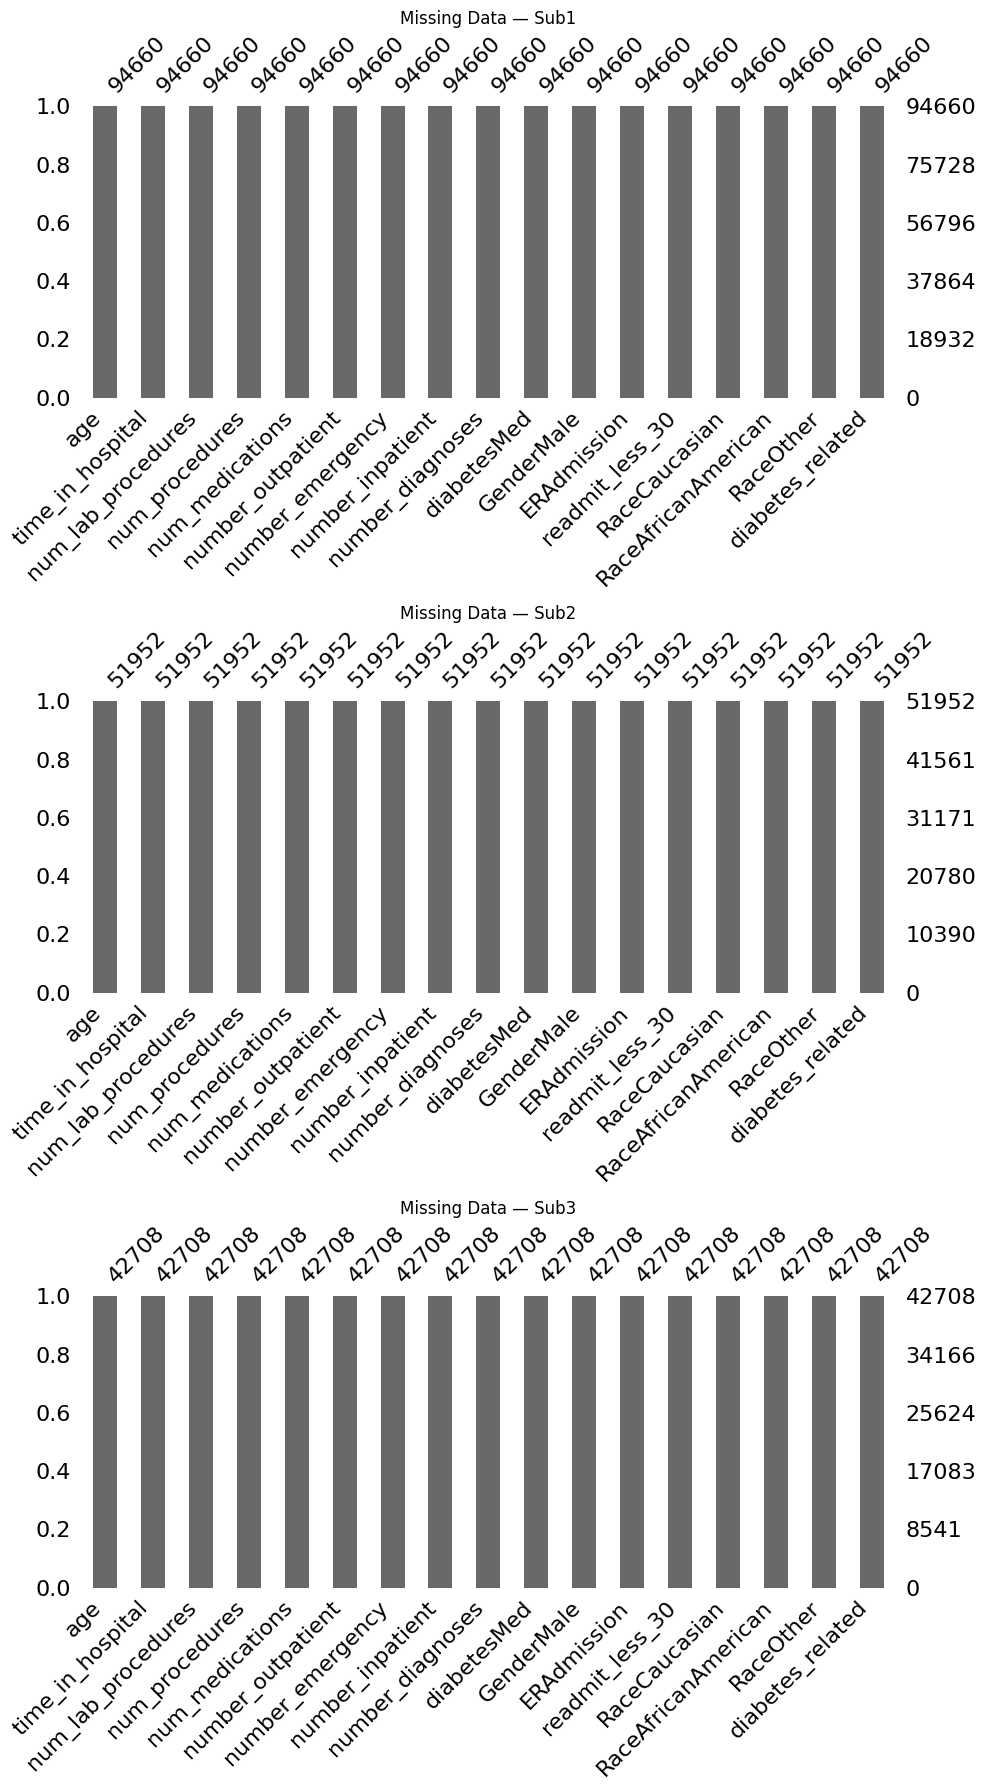

In [300]:
# Visualizing the missing data to get more idea
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

msno.bar(Sub1, ax=axes[0])
axes[0].set_title("Missing Data — Sub1")

msno.bar(Sub2, ax=axes[1])
axes[1].set_title("Missing Data — Sub2")

msno.bar(Sub3, ax=axes[2])
axes[2].set_title("Missing Data — Sub3")

plt.tight_layout()
plt.show()


In [301]:
print("Correlation Matrix for Sub1")
display(Sub1[numerical].corr())

print("\nCorrelation Matrix for Sub2")
display(Sub2[numerical].corr())

print("\nCorrelation Matrix for Sub3")
display(Sub3[numerical].corr())

Correlation Matrix for Sub1


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.318801,0.184753,0.466880,-0.006117,-0.007713,0.073310,0.219973
num_lab_procedures,0.318801,1.000000,0.050543,0.269969,-0.005300,0.000470,0.040540,0.146887
num_procedures,0.184753,0.050543,1.000000,0.373368,-0.023661,-0.038065,-0.064648,0.073689
num_medications,0.466880,0.269969,0.373368,1.000000,0.046929,0.014111,0.067475,0.265899
number_outpatient,-0.006117,-0.005300,-0.023661,0.046929,1.000000,0.089030,0.107602,0.092839
number_emergency,-0.007713,0.000470,-0.038065,0.014111,0.089030,1.000000,0.270564,0.054106
number_inpatient,0.073310,0.040540,-0.064648,0.067475,0.107602,0.270564,1.000000,0.103701
number_diagnoses,0.219973,0.146887,0.073689,0.265899,0.092839,0.054106,0.103701,1.000000



Correlation Matrix for Sub2


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.341068,0.169538,0.464583,-0.013123,-0.005760,0.077714,0.235851
num_lab_procedures,0.341068,1.000000,0.031833,0.257035,-0.011126,0.022659,0.082102,0.152524
num_procedures,0.169538,0.031833,1.000000,0.394962,-0.013612,-0.032925,-0.018562,0.092966
num_medications,0.464583,0.257035,0.394962,1.000000,0.026327,0.004411,0.041028,0.264557
number_outpatient,-0.013123,-0.011126,-0.013612,0.026327,1.000000,0.094198,0.062201,0.077097
number_emergency,-0.005760,0.022659,-0.032925,0.004411,0.094198,1.000000,0.130681,0.049909
number_inpatient,0.077714,0.082102,-0.018562,0.041028,0.062201,0.130681,1.000000,0.068957
number_diagnoses,0.235851,0.152524,0.092966,0.264557,0.077097,0.049909,0.068957,1.000000



Correlation Matrix for Sub3


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.295025,0.217812,0.467128,-0.010785,-0.022216,0.051616,0.186457
num_lab_procedures,0.295025,1.000000,0.074144,0.290661,0.001768,-0.007347,0.042725,0.147359
num_procedures,0.217812,0.074144,1.000000,0.357625,-0.020280,-0.031288,-0.053774,0.074493
num_medications,0.467128,0.290661,0.357625,1.000000,0.057924,0.009007,0.061612,0.255336
number_outpatient,-0.010785,0.001768,-0.020280,0.057924,1.000000,0.076031,0.086283,0.090134
number_emergency,-0.022216,-0.007347,-0.031288,0.009007,0.076031,1.000000,0.260372,0.037269
number_inpatient,0.051616,0.042725,-0.053774,0.061612,0.086283,0.260372,1.000000,0.057062
number_diagnoses,0.186457,0.147359,0.074493,0.255336,0.090134,0.037269,0.057062,1.000000


In [302]:
print("Correlation for Sub1 grouped by readmit_less_30")
display(Sub1.groupby('readmit_less_30')[numerical].corr())

print("\nCorrelation for Sub2 grouped by readmit_less_30")
display(Sub2.groupby('readmit_less_30')[numerical].corr())

print("\nCorrelation for Sub3 grouped by readmit_less_30")
display(Sub3.groupby('readmit_less_30')[numerical].corr())

Correlation for Sub1 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.318411   
                num_lab_procedures          0.318411            1.000000   
                num_procedures              0.177383            0.044433   
                num_medications             0.463767            0.264909   
                number_outpatient          -0.005321           -0.007330   
                number_emergency           -0.001922            0.007944   
                number_inpatient            0.080778            0.045058   
                number_diagnoses            0.222386            0.146978   
1               time_in_hospital            1.000000            0.316033   
                num_lab_procedures          0.316033            1.000000   
                num_procedures              0.250726            0.104117   
                num_medications             0.481987            0.304062   
                number_outpatient          -0.019510            0.006357   
                number_emergency           -0.053288           -0.046005   
                number_inpatient            0.012190            0.005645   
                number_diagnoses            0.183004            0.136425   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.177383         0.463767   
                num_lab_procedures        0.044433         0.264909   
                num_procedures            1.000000         0.372170   
                num_medications           0.372170         1.000000   
                number_outpatient        -0.021888         0.045872   
                number_emergency         -0.036994         0.018329   
                number_inpatient         -0.061570         0.070666   
                number_diagnoses          0.071411         0.265782   
1               time_in_hospital          0.250726         0.481987   
                num_lab_procedures        0.104117         0.304062   
                num_procedures            1.000000         0.391026   
                num_medications           0.391026         1.000000   
                number_outpatient        -0.035764         0.048712   
                number_emergency         -0.043507        -0.020284   
                number_inpatient         -0.082362         0.028821   
                number_diagnoses          0.101724         0.253038   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.005321         -0.001922   
                num_lab_procedures          -0.007330          0.007944   
                num_procedures              -0.021888         -0.036994   
                num_medications              0.045872          0.018329   
                number_outpatient            1.000000          0.089143   
                number_emergency             0.089143          1.000000   
                number_inpatient             0.107838          0.244859   
                number_diagnoses             0.092477          0.055536   
1               time_in_hospital            -0.019510         -0.053288   
                num_lab_procedures           0.006357         -0.046005   
                num_procedures              -0.035764         -0.043507   
                num_medications              0.048712         -0.020284   
                number_outpatient            1.000000          0.089737   
                number_emergency             0.089737          1.000000   
                number_inpatient             0.110119          0.320013   
                number_diagnoses             0.088538          0.033350   

                                    n


Correlation for Sub2 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.342344   
                num_lab_procedures          0.342344            1.000000   
                num_procedures              0.168514            0.030707   
                num_medications             0.463708            0.256617   
                number_outpatient          -0.012126           -0.013208   
                number_emergency           -0.003909            0.021823   
                number_inpatient            0.076800            0.077363   
                number_diagnoses            0.236415            0.152017   
1               time_in_hospital            1.000000            0.267984   
                num_lab_procedures          0.267984            1.000000   
                num_procedures              0.200984            0.063764   
                num_medications             0.464072            0.232894   
                number_outpatient          -0.050058            0.017692   
                number_emergency           -0.063616            0.010248   
                number_inpatient            0.027220            0.070465   
                number_diagnoses            0.179946            0.107008   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.168514         0.463708   
                num_lab_procedures        0.030707         0.256617   
                num_procedures            1.000000         0.395611   
                num_medications           0.395611         1.000000   
                number_outpatient        -0.014790         0.026065   
                number_emergency         -0.033723         0.005035   
                number_inpatient         -0.016937         0.038086   
                number_diagnoses          0.091062         0.265268   
1               time_in_hospital          0.200984         0.464072   
                num_lab_procedures        0.063764         0.232894   
                num_procedures            1.000000         0.387351   
                num_medications           0.387351         1.000000   
                number_outpatient         0.013432         0.021569   
                number_emergency         -0.018135        -0.024557   
                number_inpatient         -0.040483         0.027672   
                number_diagnoses          0.149029         0.217756   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.012126         -0.003909   
                num_lab_procedures          -0.013208          0.021823   
                num_procedures              -0.014790         -0.033723   
                num_medications              0.026065          0.005035   
                number_outpatient            1.000000          0.092949   
                number_emergency             0.092949          1.000000   
                number_inpatient             0.065403          0.129700   
                number_diagnoses             0.077382          0.048499   
1               time_in_hospital            -0.050058         -0.063616   
                num_lab_procedures           0.017692          0.010248   
                num_procedures               0.013432         -0.018135   
                num_medications              0.021569         -0.024557   
                number_outpatient            1.000000          0.111527   
                number_emergency             0.111527          1.000000   
                number_inpatient             0.036706          0.138972   
                number_diagnoses             0.057226          0.057489   

                                    n


Correlation for Sub3 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.286938   
                num_lab_procedures          0.286938            1.000000   
                num_procedures              0.206165            0.065238   
                num_medications             0.461580            0.281435   
                number_outpatient          -0.010355            0.000173   
                number_emergency           -0.014219            0.003391   
                number_inpatient            0.063234            0.051989   
                number_diagnoses            0.186631            0.146804   
1               time_in_hospital            1.000000            0.326535   
                num_lab_procedures          0.326535            1.000000   
                num_procedures              0.263216            0.108858   
                num_medications             0.487327            0.324986   
                number_outpatient          -0.011438            0.009832   
                number_emergency           -0.051640           -0.043864   
                number_inpatient            0.016663            0.016118   
                number_diagnoses            0.185490            0.149377   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.206165         0.461580   
                num_lab_procedures        0.065238         0.281435   
                num_procedures            1.000000         0.348170   
                num_medications           0.348170         1.000000   
                number_outpatient        -0.014855         0.059226   
                number_emergency         -0.028140         0.017695   
                number_inpatient         -0.045530         0.072308   
                number_diagnoses          0.070350         0.253488   
1               time_in_hospital          0.263216         0.487327   
                num_lab_procedures        0.108858         0.324986   
                num_procedures            1.000000         0.392740   
                num_medications           0.392740         1.000000   
                number_outpatient        -0.044090         0.054732   
                number_emergency         -0.043990        -0.020822   
                number_inpatient         -0.083096         0.029953   
                number_diagnoses          0.090903         0.262672   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.010355         -0.014219   
                num_lab_procedures           0.000173          0.003391   
                num_procedures              -0.014855         -0.028140   
                num_medications              0.059226          0.017695   
                number_outpatient            1.000000          0.074747   
                number_emergency             0.074747          1.000000   
                number_inpatient             0.081240          0.230043   
                number_diagnoses             0.089468          0.039722   
1               time_in_hospital            -0.011438         -0.051640   
                num_lab_procedures           0.009832         -0.043864   
                num_procedures              -0.044090         -0.043990   
                num_medications              0.054732         -0.020822   
                number_outpatient            1.000000          0.086202   
                number_emergency             0.086202          1.000000   
                number_inpatient             0.113771          0.325237   
                number_diagnoses             0.093984          0.029530   

                                    n

In [303]:
print("Sub1 correlation (age vs readmit_less_30)")
display(Sub1[['age', 'readmit_less_30']].corr())

print("\nSub2 correlation (age vs readmit_less_30)")
display(Sub2[['age', 'readmit_less_30']].corr())

print("\nSub3 correlation (age vs readmit_less_30)")
display(Sub3[['age', 'readmit_less_30']].corr())

Sub1 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,0.022609
readmit_less_30,0.022609,1.000000



Sub2 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,0.055804
readmit_less_30,0.055804,1.000000



Sub3 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,-0.014854
readmit_less_30,-0.014854,1.000000


### Train / Validation / Test Split using scikit-learn

In [304]:
DataTesting = Sub1.copy() #change it to sub2 or Sub3 to test each dataset

In [305]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 66262
Validation size: 14199
Test size: 14199
Total: 94660


In [306]:
DataTesting.readmit_less_30.value_counts()

readmit_less_30
0    83897
1    10763
Name: count, dtype: int64

In [307]:
train_df.readmit_less_30.value_counts()

readmit_less_30
0    58718
1     7544
Name: count, dtype: int64

In [308]:
valid_df.readmit_less_30.value_counts()

readmit_less_30
0    12600
1     1599
Name: count, dtype: int64

In [309]:
test_df.readmit_less_30.value_counts()

readmit_less_30
0    12579
1     1620
Name: count, dtype: int64

### Treating the Imbalance in the Data

Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

* Sub-sample the more dominant class: use a random subset of the negatives
* Over-sample the imbalanced class: use the same positive samples multiple times
* Create synthetic positive data

Usually, you will want to use the latter two methods if you only have a handful of positive cases. Since we have a few thousand positive cases, let's use the sub-sample approach. Here, we will create a balanced training data set that has 50% positive and 50% negative. You can also play with this ratio to see if you can get an improvement.

In [310]:
def calc_prevalence(y_actual):
    
    '''
    This function is to understand the ratio/distribution of the classes that we are going to predict for.
    
    Params:
    1. y_actual: The target feature
    
    Return:
    1. (sum(y_actual)/len(y_actual)): The ratio of the postive class in the comlpete data.
    '''
    
    return (sum(y_actual)/len(y_actual))

### WAYS TO FIX IMBALANCES

#### Random Oversampling: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.
from sklearn.utils import resample

Separate classes
df_pos = train_df[train_df['readmit_less_30'] == 1]
df_neg = train_df[train_df['readmit_less_30'] == 0]

Oversample positive class
df_pos_over = resample(
    df_pos,
    replace=True,
    n_samples=len(df_neg),
    random_state=42
)

Combine
train_balanced_over = pd.concat([df_neg, df_pos_over]).sample(frac=1, random_state=42)

#### SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(
    train_df.drop('readmit_less_30', axis=1),
    train_df['readmit_less_30']
)

#### CLASS WEIGHTS
Many machine learning algorithms allow you to assign different weights to classes during training. 
By assigning a higher weight to the minority class, you can make the model pay more attention

from sklearn.linear_model import LogisticRegression

X_train = diabetes_df_balanced.drop('readmit_less_30',axis=1)
y_train = diabetes_df_balanced['readmit_less_30']
X_valid = valid_df.drop('readmit_less_30',axis=1)
y_valid = valid_df['readmit_less_30']
X_test = test_df.drop('readmit_less_30',axis=1)
y_test = test_df['readmit_less_30']

model = LogisticRegression(class_weight='balanced', max_iter=500)
model.fit(X_train, y_train)

#### BALANCED BATCHES: 
When training models in batches (like neural networks), you can create batches that contain a balanced number of examples from each class.

from imblearn.ensemble import BalancedRandomForestClassifier

model = BalancedRandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

#### RANDOM UNDERSAMPLING

In [311]:
#split the training data into positive and negative

rows_pos = train_df['readmit_less_30'].isin([1])   # 1 is positive class
df_train_pos = train_df.loc[rows_pos]
df_train_neg = train_df.loc[~rows_pos]

# merge the balanced data
df_train_neg_sampled = df_train_neg.sample(
    n=len(df_train_pos),
    random_state=111
)

diabetes_df_balanced = pd.concat(
    [df_train_pos, df_train_neg_sampled],
    axis=0
)

# shuffle
diabetes_df_balanced = diabetes_df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(
    'Train balanced prevalence (n = %d): %.3f' %
    (len(diabetes_df_balanced),
     calc_prevalence(diabetes_df_balanced['readmit_less_30'].values))
)


Train balanced prevalence (n = 15088): 0.500


In [312]:
diabetes_df_balanced.readmit_less_30.value_counts()

readmit_less_30
1    7544
0    7544
Name: count, dtype: int64

In [313]:
X_train = diabetes_df_balanced.drop('readmit_less_30',axis=1)

y_train = diabetes_df_balanced['readmit_less_30']

X_valid = valid_df.drop('readmit_less_30',axis=1)

y_valid = valid_df['readmit_less_30']

X_test = test_df.drop('readmit_less_30',axis=1)

y_test = test_df['readmit_less_30']

In [340]:
Sub1.columns

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale',
       'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanAmerican', 'RaceOther', 'diabetes_related'],
      dtype='str')

In [341]:
set1 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_inpatient'
]


set2 = [
    'age',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'ERAdmission'
]


set3 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'ERAdmission'
]


set4 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'diabetesMed',
    'RaceCaucasian',
    'RaceAfricanAmerican',
    'RaceOther',
    'GenderMale',
    'ERAdmission'
]


In [342]:
scale_cols = set4

# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [343]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,ERAdmission,RaceCaucasian,RaceAfricanAmerican,RaceOther,diabetes_related
0,-0.057166,1.172077,71,4,-0.665465,-0.331977,-0.233325,-0.537243,-1.350692,0.514810,1.070622,0.618421,-1.738503,2.061511,-0.248421,0
1,-1.303593,-1.179156,19,6,-0.416687,-0.331977,-0.233325,-0.537243,0.775967,0.514810,-0.934037,-1.617021,0.575207,-0.485081,-0.248421,0
2,0.566047,0.836186,51,1,0.329645,-0.331977,-0.233325,-0.537243,0.775967,-1.942466,-0.934037,0.618421,0.575207,-0.485081,-0.248421,0
3,0.566047,3.187419,60,1,0.329645,-0.331977,-0.233325,0.673862,0.775967,0.514810,1.070622,0.618421,0.575207,-0.485081,-0.248421,0
4,-0.057166,-1.179156,21,0,-0.416687,-0.331977,0.584803,0.068309,-0.819027,0.514810,-0.934037,-1.617021,0.575207,-0.485081,-0.248421,0


## Creating and Understanding Models

In [344]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

## Linear Regression

In [345]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [346]:
print(y_valid_preds)

[0.33656686 0.42964352 0.55860876 0.47101852 0.4857592  0.46671261
 0.48951152 0.36226307 0.4367369  0.54803596 0.45391086 0.52043227
 0.38069056 0.28839979 0.58602414 0.66064602 0.37627348 0.4630985
 0.59945023 0.59502946 0.47578375 0.6020563  0.70289267 0.42193456
 0.36756616 0.58207422 0.43311411 0.24243524 0.44750918 0.53515482
 0.41112414 0.51856119 0.32626449 0.45497609 0.4532293  0.46761332
 0.49442374 0.40522196 0.40459403 0.35898001 0.39698481 0.38599828
 0.52459061 0.42850537 0.47392771 0.43072256 0.45710067 0.50383565
 0.50325857 0.62155631 0.51810299 0.3529235  0.43037481 0.52352354
 0.53384544 0.45112808 0.49858977 0.42040806 0.52369476 0.44448573
 0.46170984 0.44115673 0.4473678  0.47432606 0.36429837 0.57589835
 0.46738051 0.37307309 0.49547587 0.35931189 0.62834568 0.29763962
 0.42365502 0.55402933 0.42329413 0.51886046 0.49773066 0.45696893
 0.4865651  0.56793989 0.45793918 0.52921391 0.40640522 0.53785946
 0.48097192 0.38775162 0.55193025 0.32564499 0.5491818  0.51058

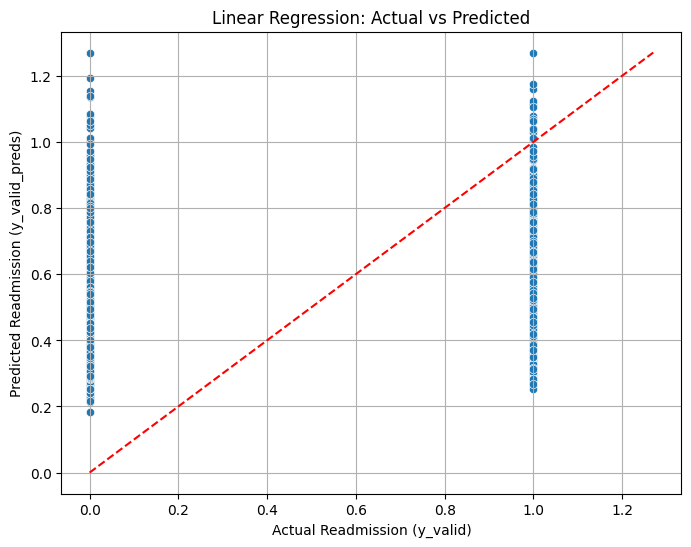

In [321]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


## Logistic Regression

In [322]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.647
accuracy:0.652
recall:0.530
precision:0.168
specificity:0.667
prevalence:0.113
 


## KNN Model

In [323]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.596
accuracy:0.610
recall:0.503
precision:0.145
specificity:0.568
prevalence:0.113
 


## Stochastic Gradient Descent Model

In [324]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.643
accuracy:0.691
recall:0.470
precision:0.175
specificity:0.719
prevalence:0.113
 


## Decision Tree

In [325]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.606
accuracy:0.524
recall:0.645
precision:0.143
specificity:0.501
prevalence:0.113
 


## Random Forest

In [326]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.649
accuracy:0.614
recall:0.585
precision:0.163
specificity:0.618
prevalence:0.113
 


## Linear SVC

In [327]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.645
accuracy:0.882
recall:0.078
precision:0.388
specificity:0.984
prevalence:0.113
 


## Gradient Boosting Model

In [328]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.613
accuracy:0.580
recall:0.580
precision:0.149
specificity:0.580
prevalence:0.113
 


## XGB Model

In [329]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.617
accuracy:0.584
recall:0.573
precision:0.149
specificity:0.585
prevalence:0.113
 


## Catboost Model

In [330]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.6658865	total: 3.7ms	remaining: 737ms
1:	learn: 0.6625343	total: 7.28ms	remaining: 721ms
2:	learn: 0.6599638	total: 10.2ms	remaining: 673ms
3:	learn: 0.6594759	total: 13ms	remaining: 636ms
4:	learn: 0.6589674	total: 16.1ms	remaining: 628ms
5:	learn: 0.6584291	total: 19.5ms	remaining: 629ms
6:	learn: 0.6577814	total: 22.6ms	remaining: 623ms
7:	learn: 0.6569305	total: 26.2ms	remaining: 630ms
8:	learn: 0.6563997	total: 28.9ms	remaining: 613ms
9:	learn: 0.6558989	total: 32.1ms	remaining: 610ms
10:	learn: 0.6550270	total: 35.9ms	remaining: 616ms
11:	learn: 0.6537922	total: 38.7ms	remaining: 606ms
12:	learn: 0.6527536	total: 41.9ms	remaining: 602ms
13:	learn: 0.6517670	total: 44.4ms	remaining: 591ms
14:	learn: 0.6511664	total: 48.5ms	remaining: 599ms
15:	learn: 0.6503308	total: 51.4ms	remaining: 591ms
16:	learn: 0.6499472	total: 54.6ms	remaining: 587ms
17:	learn: 0.6494876	total: 57.5ms	remaining: 582ms
18:	learn: 0.6488782	total: 60.4ms	remaining: 575ms
19:	learn: 0.6483058	tota

## Decision Tree - Hyper Parameter Tuning

In [331]:
recall_scoring = make_scorer(recall_score)

In [332]:
dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid, 
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.6203312834410395

In [333]:
recall_score(y_valid, dc_hp_preds)

0.5928705440900562

## Random Forest - Hyper Parameter Tuning

In [334]:
rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid, 
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.6516772387504095

In [335]:
recall_score(y_valid, rf_hp_preds)

0.6078799249530957

## XGBoost - Hyper Parameter Tuning

In [336]:
xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid, 
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.6383869382649872

In [337]:
recall_score(y_valid, xgb_hp_preds)

0.6122576610381488

### Hyper Parameter Tuning
Across the models I tuned, the overall improvements were modest, and none of the algorithms showed a dramatic performance jump after tuning. The tuned scores generally stayed in the low to mid 0.62 range, which is consistent with the baseline performance of the dataset. Random Forest and XGBoost performed the strongest after tuning, with scores around 0.6296 and 0.6274, and both maintained recall values just above 0.54 to 0.55, meaning they captured slightly more true cases than the other models. The general pattern across all tuned models shows that while tuning helped stabilize performance, it didn’t fundamentally change the predictive power of the algorithms. 

Overall, hyperparameter tuning confirmed that the dataset supports only modest discrimination, and even the best tuned models remain limited in their ability to reliably identify positive cases.

### Summary of Model Results and Findings
Across all the models I tested, the overall predictive performance was modest, with most algorithms showing AUC values in the low to mid 0.60 range. This tells me that none of the models were able to strongly separate higher and lower  risk patients. Accuracy was consistently inflated by the low prevalence of the outcome, so it wasn’t a reliable indicator of true performance. Recall values generally hovered around the 0.50 range for most models, meaning they captured only about half of the actual positive cases, while precision remained low across the board, reflecting the difficulty of making correct positive predictions in a low prevalence setting. Specificity tended to be higher than recall, showing that the models were more comfortable predicting “no” than “yes.” Even with hyperparameter tuning, improvements were small and didn’t fundamentally change the behavior of the models. 

Overall, the findings suggest that while the models show some signal, their ability to reliably identify true positive cases is limited, and the dataset supports only modest discrimination regardless of algorithm or tuning.

In [338]:
# ============================================================
#  Collect metrics into a list for table creation
# ============================================================

results = []

def add_result(model_name, auc, acc, rec, prec, spec, prev):
    results.append({
        "Model": model_name,
        "AUC": auc,
        "Accuracy": acc,
        "Recall": rec,
        "Precision": prec,
        "Specificity": spec,
        "Prevalence": prev
    })


# ============================================================
# 1. Logistic Regression
# ============================================================
lr = LogisticRegression(random_state=42, solver='newton-cg', max_iter=200)
lr.fit(X_train, y_train)

lr_preds = lr.predict_proba(X_valid)[:, 1]

lr_auc, lr_acc, lr_rec, lr_prec, lr_spec = print_report(y_valid, lr_preds, 0.5)
prev = y_valid.mean()

add_result("Logistic Regression", lr_auc, lr_acc, lr_rec, lr_prec, lr_spec, prev)


# ============================================================
# 2. KNN
# ============================================================
knn = KNeighborsClassifier(n_neighbors=100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:, 1]

knn_auc, knn_acc, knn_rec, knn_prec, knn_spec = print_report(y_valid, knn_preds, 0.5)

add_result("KNN (k=100)", knn_auc, knn_acc, knn_rec, knn_prec, knn_spec, prev)


# ============================================================
# 3. SGDClassifier
# ============================================================
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgdc_preds = sgdc.predict_proba(X_valid)[:, 1]

sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec = print_report(y_valid, sgdc_preds, 0.5)

add_result("SGDClassifier", sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec, prev)


# ============================================================
# 4. Decision Tree
# ============================================================
dc_clf = DecisionTreeClassifier(random_state=42, max_depth=10)
dc_clf.fit(X_train, y_train)

dc_preds = dc_clf.predict_proba(X_valid)[:, 1]

dc_auc, dc_acc, dc_rec, dc_prec, dc_spec = print_report(y_valid, dc_preds, 0.5)

add_result("Decision Tree (max_depth=10)", dc_auc, dc_acc, dc_rec, dc_prec, dc_spec, prev)


# ============================================================
# 5. Random Forest
# ============================================================
rf_clf = RandomForestClassifier(random_state=111, max_depth=6)
rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict_proba(X_valid)[:, 1]

rf_auc, rf_acc, rf_rec, rf_prec, rf_spec = print_report(y_valid, rf_preds, 0.5)

add_result("Random Forest (max_depth=6)", rf_auc, rf_acc, rf_rec, rf_prec, rf_spec, prev)


# ============================================================
# 6. Linear SVC
# ============================================================
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec = print_report(y_valid, lsvc_preds, 0.5)

add_result("Linear SVC", lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec, prev)


# ============================================================
# 7. Gradient Boosting
# ============================================================
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    criterion='friedman_mse',
    learning_rate=1.0,
    max_depth=3,
    random_state=111
)
gb_clf.fit(X_train, y_train)

gb_preds = gb_clf.predict_proba(X_valid)[:, 1]

gb_auc, gb_acc, gb_rec, gb_prec, gb_spec = print_report(y_valid, gb_preds, 0.5)

add_result("Gradient Boosting", gb_auc, gb_acc, gb_rec, gb_prec, gb_spec, prev)


# ============================================================
# 8. XGBoost
# ============================================================
xgb_clf = xgb.XGBClassifier(
    max_depth=3,
    learning_rate=1.0,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict_proba(X_valid)[:, 1]

xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec = print_report(y_valid, xgb_preds, 0.5)

add_result("XGBoost", xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec, prev)


# ============================================================
# FINAL TABLE
# ============================================================
results_df = pd.DataFrame(results)
print("\n\n===== MODEL PERFORMANCE TABLE =====\n")
print(results_df)

AUC:0.647
accuracy:0.652
recall:0.530
precision:0.168
specificity:0.667
prevalence:0.113
 
AUC:0.596
accuracy:0.610
recall:0.503
precision:0.145
specificity:0.568
prevalence:0.113
 
AUC:0.643
accuracy:0.691
recall:0.470
precision:0.175
specificity:0.719
prevalence:0.113
 
AUC:0.606
accuracy:0.524
recall:0.645
precision:0.143
specificity:0.501
prevalence:0.113
 
AUC:0.649
accuracy:0.614
recall:0.585
precision:0.163
specificity:0.618
prevalence:0.113
 
AUC:0.645
accuracy:0.882
recall:0.078
precision:0.388
specificity:0.984
prevalence:0.113
 
AUC:0.613
accuracy:0.580
recall:0.580
precision:0.149
specificity:0.580
prevalence:0.113
 
AUC:0.617
accuracy:0.584
recall:0.573
precision:0.149
specificity:0.585
prevalence:0.113
 


===== MODEL PERFORMANCE TABLE =====

                          Model       AUC  Accuracy    Recall  Precision  \
0           Logistic Regression  0.646695  0.651666  0.530331   0.168154   
1                   KNN (k=100)  0.596060  0.610395  0.503440   0.145228   
2    

In [339]:
results_df

,Model,AUC,Accuracy,Recall,Precision,Specificity,Prevalence
0,Logistic Regression,0.646695,0.651666,0.530331,0.168154,0.667063,0.112614
1,KNN (k=100),0.596060,0.610395,0.503440,0.145228,0.568175,0.112614
2,SGDClassifier,0.642717,0.691246,0.469669,0.175181,0.719365,0.112614
3,Decision Tree (max_depth=10),0.606311,0.523628,0.644778,0.142659,0.501429,0.112614
4,Random Forest (max_depth=6),0.649478,0.614057,0.584740,0.162580,0.617778,0.112614
5,Linear SVC,0.644859,0.882316,0.077548,0.387500,0.984444,0.112614
6,Gradient Boosting,0.613046,0.580393,0.580363,0.149316,0.580397,0.112614
7,XGBoost,0.617260,0.583774,0.572858,0.149113,0.585159,0.112614
